# UC2 — Caderno de Estudos: Aulas 1 a 5

**Criar e Manipular Dados Utilizando Matemática Estatística** · Analista de Dados · SENAC RJ
Prof. Cassio Ribeiro

Este caderno reúne, em um só lugar, tudo o que foi visto nas Aulas 1 a 5: ambiente e DataFrame, exploração e quartis, média e mediana, outliers e visualização com Matplotlib.

**Como usar**

- As células de **código com exemplos prontos** devem ser executadas e lidas com atenção. Altere valores e rode de novo para ver o que muda.
- As **Atividades** têm o enunciado em linguagem de negócio e uma célula de código **em branco**: o código é seu. Use o que foi visto nas aulas.
- Execute as células **na ordem**, de cima para baixo: os exemplos criam variáveis que as seções seguintes usam.

**Bases usadas**

| Base | Arquivo / origem | Uso |
|---|---|---|
| Vendas do NaraStore | `vendas_narastore.xlsx` (mesma pasta deste caderno) | Aula 1, 3 e 5 |
| Ocorrências do ISP-RJ | link do Instituto de Segurança Pública do RJ | Aulas 2 a 5 |

**Sumário**

1. Preparando o ambiente
2. Aula 1 — Ambiente virtual, Jupyter e DataFrame
3. Aula 2 — Explorando dados: groupby e quartis
4. Aula 3 — Média, mediana e a distância entre elas
5. Aula 4 — Outliers e IQR
6. Aula 5 — Visualização com Matplotlib e subplots

## 0. Preparando o ambiente

Cada projeto deve ter o seu **ambiente virtual (VEnv)**, isolado das demais instalações do computador. No CMD do Windows, dentro da pasta do projeto:

```
python -m venv venv
venv\Scripts\activate
pip install pandas numpy matplotlib openpyxl ipykernel
```

Para sair do ambiente: `deactivate`. Para registrar as bibliotecas do projeto e recriá-las em outra máquina:

```
pip freeze > requirements.txt
pip install -r requirements.txt
```

No VS Code, ao abrir este arquivo `.ipynb`, escolha o **kernel** do seu VEnv (canto superior direito do caderno).

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

print('Matplotlib', matplotlib.__version__)

Matplotlib 3.11.2


Este caderno usa **Matplotlib 3.10 ou superior** (por causa do parâmetro `orientation` do boxplot, visto na Aula 5). Se a versão for menor, atualize com `pip install -U matplotlib`.

---
# Aula 1 — Ambiente virtual, Jupyter e DataFrame

## 1.1 Variáveis qualitativas e quantitativas

Antes de analisar dados, precisamos saber que **tipo de informação** cada coluna guarda.

| Tipo | O que descreve | Exemplos |
|---|---|---|
| **Qualitativa** | uma categoria, um rótulo | nome do produto, cidade, cor |
| **Quantitativa** | uma quantidade, um número que pode ser medido e calculado | vendas, idade, preço |

Regra prática: se faz sentido **somar ou tirar a média**, a variável é quantitativa. Se só faz sentido **agrupar e contar**, é qualitativa.

## 1.2 O Jupyter Notebook

Um caderno é formado por **células**. Existem dois tipos que usamos aqui:

- **Código**: executa Python;
- **Markdown**: texto explicativo (como esta célula).

Atalhos para executar uma célula de código: `Shift + Enter` executa e avança para a próxima; `Ctrl + Enter` executa e permanece na mesma.

Para mostrar resultados, há duas formas. O `print()` escreve texto simples; o `display()` mostra o objeto de forma formatada, como uma tabela quando for um DataFrame.

## 1.3 Dicionário: a base de um DataFrame manual

Para criar um DataFrame à mão, sem dados externos, o **dicionário** é a melhor estrutura: as **chaves** viram os nomes das colunas e os **valores** (listas) viram os dados de cada coluna.

In [3]:
dados_exemplo = {
    'vendedor': ['Ana', 'Carlos', 'Beatriz'],
    'total':    [1500, 2300, 1800]
}

df_exemplo = pd.DataFrame(dados_exemplo)

print(df_exemplo)
display(df_exemplo)

  vendedor  total
0      Ana   1500
1   Carlos   2300
2  Beatriz   1800


,vendedor,total
0,Ana,1500
1,Carlos,2300
2,Beatriz,1800


Compare as duas saídas: o `print()` mostra texto; o `display()` mostra uma tabela formatada. Um DataFrame funciona como uma planilha do Excel: tem linhas e colunas, cada linha com um número de índice.

## 1.4 Lendo uma planilha do Excel

Na prática, os dados vêm de arquivos. Para ler `.xlsx` com o Pandas usamos `pd.read_excel()`; ele depende do pacote **openpyxl** (`pip install openpyxl`).

O arquivo `vendas_narastore.xlsx` tem **duas tabelas na mesma aba**: as vendas (colunas A a G) e as metas por vendedor (colunas J e K). Com o parâmetro `usecols` lemos apenas o intervalo que nos interessa.

In [4]:
df = pd.read_excel('vendas_narastore.xlsx', usecols='A:G')

display(df)

,Data,Vendedor,Produto,Categoria,Quantidade,Valor Unit. (R$),Total (R$)
0,10/03/2025,Ana Lima,Notebook Dell,Eletrônicos,1,3200.0,3200.0
1,10/03/2025,Carlos Souza,Mouse Sem Fio,Periféricos,3,89.9,269.7
2,11/03/2025,Beatriz Nunes,Cadeira Gamer,Móveis,2,750.0,1500.0
3,11/03/2025,Ana Lima,"Monitor 24""",Eletrônicos,1,980.0,980.0
4,12/03/2025,Diego Ferreira,Teclado Mecânico,Periféricos,2,320.0,640.0
5,12/03/2025,Carlos Souza,Headset Gamer,Periféricos,1,450.0,450.0
6,13/03/2025,Beatriz Nunes,Notebook Dell,Eletrônicos,1,3200.0,3200.0
7,13/03/2025,Diego Ferreira,Mesa de Escritório,Móveis,1,1200.0,1200.0
8,14/03/2025,Ana Lima,Mouse Sem Fio,Periféricos,5,89.9,449.5
9,14/03/2025,Carlos Souza,"Monitor 24""",Eletrônicos,2,980.0,1960.0


## 1.5 Operações básicas com uma coluna

Cada coluna é uma **Série** e aceita métodos como `sum()` (soma), `mean()` (média), `max()` (maior valor) e `min()` (menor valor).

In [5]:
total = df['Total (R$)'].sum()
media_venda = df['Total (R$)'].mean()
maior_venda = df['Total (R$)'].max()
menor_venda = df['Total (R$)'].min()

print(f'Total vendido: R$ {total:.2f}')
print(f'Média por venda: R$ {media_venda:.2f}')
print(f'Maior venda: R$ {maior_venda:.2f}')
print(f'Menor venda: R$ {menor_venda:.2f}')

Total vendido: R$ 28268.80
Média por venda: R$ 1413.44
Maior venda: R$ 3200.00
Menor venda: R$ 269.70


### Atividade 1.1 — Classificando as variáveis

Para cada coluna da base do NaraStore, indique se a variável é **qualitativa** ou **quantitativa**. Escreva a sua resposta nesta célula, editando a tabela.

| Coluna | Tipo |
|---|---|
| Data | |
| Vendedor | |
| Produto | |
| Categoria | |
| Quantidade | |
| Valor Unit. (R$) | |
| Total (R$) | |

### Atividade 1.2 — Resumo de vendas do NaraStore

Você acaba de entrar como estagiário(a) na equipe comercial do NaraStore. O analista sênior deixou o relatório de vendas de março/2025 e pediu que você prepare o ambiente, carregue os dados e responda:

1. Qual foi o total vendido no período?
2. Qual foi o valor médio por venda?
3. Qual foi a maior venda individual e qual foi a menor?

Documente cada passo com células de texto.

In [6]:
# Escreva seu código aqui

In [7]:
# Escreva seu código aqui

**Sua conclusão:** *(escreva aqui, em uma ou duas frases)*

---
# Aula 2 — Explorando dados: groupby e quartis

Agora vamos trabalhar com uma base real: as **ocorrências registradas pelas delegacias do estado do Rio de Janeiro**, divulgadas pelo ISP-RJ (Instituto de Segurança Pública). Cada linha traz os números de um mês em uma **CISP** (circunscrição de delegacia).

## 2.1 Carregando a base do ISP-RJ

O Pandas lê o arquivo direto do link. Dois parâmetros são necessários:

- `encoding='latin-1'`: a codificação de caracteres do arquivo (acentos);
- `sep=';'`: o separador de colunas, que neste arquivo é o ponto e vírgula.

In [8]:
url = 'https://www.ispdados.rj.gov.br/Arquivos/BaseDPEvolucaoMensalCisp.csv'

isp = pd.read_csv(url, encoding='latin-1', sep=';')

## 2.2 Explorando o DataFrame

In [9]:
print(isp.shape)

(38547, 65)


`shape` devolve (linhas, colunas). Para ver as primeiras linhas das colunas que vamos usar:

In [10]:
isp[['cisp', 'ano', 'mes', 'regiao', 'munic', 'furto_celular', 'roubo_veiculo']].head()

,cisp,ano,mes,regiao,munic,furto_celular,roubo_veiculo
0,1,2003,1,Capital,Rio de Janeiro,37,5
1,4,2003,1,Capital,Rio de Janeiro,23,9
2,5,2003,1,Capital,Rio de Janeiro,47,11
3,6,2003,1,Capital,Rio de Janeiro,8,27
4,7,2003,1,Capital,Rio de Janeiro,1,23


`info()` mostra o tipo de cada coluna e quantos valores existem; `describe()` resume as colunas numéricas (contagem, média, desvio, mínimo, quartis e máximo).

In [11]:
isp[['cisp', 'ano', 'regiao', 'munic', 'furto_celular', 'roubo_veiculo']].info()

<class 'pandas.DataFrame'>
RangeIndex: 38547 entries, 0 to 38546
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   cisp           38547 non-null  int64
 1   ano            38547 non-null  int64
 2   regiao         38547 non-null  str  
 3   munic          38547 non-null  str  
 4   furto_celular  38547 non-null  int64
 5   roubo_veiculo  38547 non-null  int64
dtypes: int64(4), str(2)
memory usage: 1.8 MB


In [12]:
isp[['furto_celular', 'roubo_veiculo']].describe()

,furto_celular,roubo_veiculo
count,38547.000000,38547.000000
mean,12.983501,18.952629
std,26.271915,32.926444
min,0.000000,0.000000
25%,1.000000,0.000000
50%,5.000000,3.000000
75%,15.000000,24.000000
max,1008.000000,394.000000


## 2.3 Variáveis desta base

- **Qualitativas:** `cisp` (código da delegacia), `regiao`, `munic` (município);
- **Quantitativas:** os contadores de ocorrências, como `furto_celular`, `roubo_veiculo`, `furto_veiculos` e `recuperacao_veiculos`;
- **Tempo:** `ano`, `mes` e `mes_ano`.

## 2.4 Selecionando linhas e colunas: loc e query

- `loc[linhas, colunas]` seleciona por **rótulo** (nomes de colunas, índices);
- `query()` filtra linhas com uma condição escrita como texto.

In [13]:
isp.loc[0:4, ['cisp', 'munic', 'furto_celular']]

,cisp,munic,furto_celular
0,1,Rio de Janeiro,37
1,4,Rio de Janeiro,23
2,5,Rio de Janeiro,47
3,6,Rio de Janeiro,8
4,7,Rio de Janeiro,1


In [14]:
capital = isp.query("regiao == 'Capital' and ano == 2024")

capital[['cisp', 'mes', 'furto_celular']].head()

,cisp,mes,furto_celular
33889,1,1,156
33890,4,1,131
33891,5,1,266
33892,6,1,40
33893,7,1,19


Neste filtro usamos `and` para combinar duas condições: região **e** ano.

## 2.5 Agrupando: groupby, sum, reset_index e sort_values

Os dados são mensais por CISP. Para saber **quanto cada CISP registrou em 2024**, agrupamos por CISP e somamos:

- `groupby('cisp')` separa as linhas por CISP;
- `['furto_celular'].sum()` soma a coluna em cada grupo;
- `reset_index()` transforma o resultado de volta em um DataFrame comum;
- `sort_values(by=..., ascending=False)` ordena do maior para o menor.

In [15]:
por_cisp = capital.groupby('cisp')['furto_celular'].sum().reset_index()
por_cisp = por_cisp.sort_values(by='furto_celular', ascending=False)

display(por_cisp.head(10))

,cisp,furto_celular
12,16,2305
2,5,2259
14,18,2059
10,14,1683
6,10,1629
8,12,1624
5,9,1599
1,4,1500
0,1,1104
28,32,948


## 2.6 Do DataFrame para o array: média e mediana com NumPy

Para os cálculos estatísticos, transformamos a coluna em um **array** do NumPy.

In [16]:
dados = np.array(por_cisp['furto_celular'])

media = np.mean(dados)
mediana = np.median(dados)

print('Quantidade de CISPs:', len(dados))
print('Média:', media)
print('Mediana:', mediana)

Quantidade de CISPs: 41
Média: 717.609756097561
Mediana: 535.0


## 2.7 Quartis: Q1, Q2 e Q3

Os **quartis** dividem os dados ordenados em quatro partes iguais:

- **Q1** (25%): 25% dos valores estão abaixo dele;
- **Q2** (50%): é a **mediana**, o valor do meio;
- **Q3** (75%): 75% dos valores estão abaixo dele.

Calculamos cada um com `np.percentile()`, em variáveis separadas.

In [17]:
q1 = np.percentile(dados, 25)
q2 = np.percentile(dados, 50)
q3 = np.percentile(dados, 75)

print('Q1:', q1)
print('Q2 (mediana):', q2)
print('Q3:', q3)

Q1: 230.0
Q2 (mediana): 535.0
Q3: 859.0


## 2.8 Usando o quartil para filtrar: os 25% maiores

Os valores acima do Q3 formam o grupo dos **25% de CISPs com mais ocorrências**. Para filtrar, escrevemos a condição entre colchetes.

In [18]:
top25 = por_cisp[por_cisp['furto_celular'] > q3]

display(top25)

,cisp,furto_celular
12,16,2305
2,5,2259
14,18,2059
10,14,1683
6,10,1629
8,12,1624
5,9,1599
1,4,1500
0,1,1104
28,32,948


### Atividade 2.1 — Roubo de veículos na Baixada Fluminense

A gerência de uma seguradora quer entender onde o roubo de veículos se concentra na **Baixada Fluminense** em **2024** (variável `roubo_veiculo`).

1. Monte o ranking dos municípios, do que mais registrou ao que menos registrou.
2. Calcule Q1, Q2 e Q3 do total por município.
3. Quais municípios formam o grupo dos 25% com mais roubos de veículos?

In [19]:
# Escreva seu código aqui

In [20]:
# Escreva seu código aqui

In [21]:
# Escreva seu código aqui

**Sua conclusão:** *(escreva aqui, em uma ou duas frases)*

### Atividade 2.2 — Furto de veículos na Baixada Fluminense

Repita a análise para a variável `furto_veiculos`, ainda na Baixada Fluminense em 2024, agora comparando as **CISPs** em vez dos municípios. Existe diferença entre as CISPs que lideram os furtos e as que lideram os roubos de veículos?

In [22]:
# Escreva seu código aqui

In [23]:
# Escreva seu código aqui

In [24]:
# Escreva seu código aqui

**Sua conclusão:** *(escreva aqui, em uma ou duas frases)*

---
# Aula 3 — Média, mediana e a distância entre elas

## 3.1 Medidas de tendência central

As medidas de tendência central resumem um conjunto de dados em **um valor que representa o centro**:

- **Média:** soma de todos os valores dividida pela quantidade. É sensível a valores extremos;
- **Mediana:** valor do meio quando os dados estão ordenados (igual ao Q2). Quase não é afetada por extremos.

Retomando o array da Capital em 2024 (furtos de celular por CISP):

In [25]:
dados = np.array(por_cisp['furto_celular'])

media = np.mean(dados)
mediana = np.median(dados)

print(f'Média: {media:.1f}')
print(f'Mediana: {mediana:.1f}')

Média: 717.6
Mediana: 535.0


A média é bem maior do que a mediana. Será que a média é uma boa representante desses dados? Para responder, vamos medir **a distância entre as duas**.

## 3.2 A distância entre média e mediana

$$\text{distância} = \frac{\text{média} - \text{mediana}}{\text{mediana}}$$

O resultado, em porcentagem, indica se a média é confiável:

| Distância (valor absoluto) | Leitura |
|---|---|
| até 10% | a média tende a ser uma medida **confiável** |
| de 10% até 25% | os valores extremos influenciam a média **moderadamente**; pode ser que ela seja confiável, ou não |
| 25% ou mais | os extremos influenciam **muito** a média; ela tende a **não** ser confiável |

**Direção da influência:** se a média é **maior** que a mediana, os valores **maiores** estão puxando a média; se é **menor**, são os valores **menores**.

In [26]:
distancia = (media - mediana) / mediana

print(f'Distância: {distancia:.1%}')

Distância: 34.1%


In [27]:
if abs(distancia) <= 0.10:
    leitura = 'média confiável'
elif abs(distancia) < 0.25:
    leitura = 'influência moderada dos extremos'
else:
    leitura = 'média não confiável'

if media > mediana:
    direcao = 'os valores maiores puxam a média'
else:
    direcao = 'os valores menores puxam a média'

print(leitura)
print(direcao)

média não confiável
os valores maiores puxam a média


Nos furtos de celular por CISP na Capital, a distância passa de 25%: a média **não** representa bem o conjunto, porque as CISPs com muitos registros a puxam para cima. Nesse caso, a **mediana** é a melhor medida de tendência central.

## 3.3 Coluna derivada

Podemos criar uma coluna nova a partir de outras. No NaraStore, vamos recalcular o total de cada venda como **quantidade × valor unitário**:

In [28]:
df['Total calculado (R$)'] = df['Quantidade'] * df['Valor Unit. (R$)']

df[['Produto', 'Quantidade', 'Valor Unit. (R$)', 'Total calculado (R$)']].head()

,Produto,Quantidade,Valor Unit. (R$),Total calculado (R$)
0,Notebook Dell,1,3200.0,3200.0
1,Mouse Sem Fio,3,89.9,269.7
2,Cadeira Gamer,2,750.0,1500.0
3,"Monitor 24""",1,980.0,980.0
4,Teclado Mecânico,2,320.0,640.0


### Atividade 3.1 — O ticket médio do NaraStore

Em uma reunião, o gerente comercial afirmou: "a média de valor das nossas vendas representa bem o que o NaraStore vende". Verifique a afirmação com os dados da coluna `Total (R$)`. A média é uma boa medida de tendência central? Apresente os cálculos e uma conclusão objetiva.

In [29]:
# Escreva seu código aqui

In [30]:
# Escreva seu código aqui

**Sua conclusão:** *(escreva aqui, em uma ou duas frases)*

### Atividade 3.2 — Roubo de celular na Capital

A secretaria quer usar um único número para resumir o roubo de celular por CISP na **Capital** em **2024** (variável `roubo_celular`). Calcule o total por CISP, a média e a mediana, e a distância entre elas. Qual medida deve ser usada como resumo? Os valores maiores ou os menores puxam a média?

In [31]:
# Escreva seu código aqui

In [32]:
# Escreva seu código aqui

In [33]:
# Escreva seu código aqui

**Sua conclusão:** *(escreva aqui, em uma ou duas frases)*

### Atividade 3.3 — Roubo de veículos por município na Baixada

Repita a verificação para o total de `roubo_veiculo` por **município** da Baixada Fluminense em 2024. Compare a distância encontrada com a do exercício anterior e explique o que muda na confiabilidade da média.

In [34]:
# Escreva seu código aqui

In [35]:
# Escreva seu código aqui

In [36]:
# Escreva seu código aqui

**Sua conclusão:** *(escreva aqui, em uma ou duas frases)*

---
# Aula 4 — Outliers e IQR

**Outliers** são valores muito acima ou muito abaixo dos demais. Em dados de negócio costumam responder perguntas como: quais produtos venderam muito mais (ou muito menos) que os outros? Quais delegacias registraram bem mais ocorrências que as demais?

## 4.1 O intervalo interquartil (IQR)

O **IQR** é a distância entre Q3 e Q1 e representa os 50% centrais dos dados.

$$\text{IQR} = Q3 - Q1$$

Os **limites** que separam os valores normais dos outliers são:

$$\text{limite superior} = Q3 + 1{,}5 \times \text{IQR} \qquad \text{limite inferior} = Q1 - 1{,}5 \times \text{IQR}$$

Valores **acima do limite superior** são outliers superiores; valores **abaixo do limite inferior** são outliers inferiores.

In [37]:
q1 = np.percentile(dados, 25)
q3 = np.percentile(dados, 75)

iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr
limite_inferior = q1 - 1.5 * iqr

print('IQR:', iqr)
print('Limite superior:', limite_superior)
print('Limite inferior:', limite_inferior)

IQR: 629.0
Limite superior: 1802.5
Limite inferior: -713.5


## 4.2 Encontrando os outliers

Usamos filtros no DataFrame `por_cisp` (furtos de celular por CISP na Capital, 2024) e ordenamos com `sort_values()`.

In [38]:
outliers_superiores = por_cisp[por_cisp['furto_celular'] > limite_superior]
outliers_superiores = outliers_superiores.sort_values(by='furto_celular', ascending=False)

display(outliers_superiores)

,cisp,furto_celular
12,16,2305
2,5,2259
14,18,2059


In [39]:
outliers_inferiores = por_cisp[por_cisp['furto_celular'] < limite_inferior]
outliers_inferiores = outliers_inferiores.sort_values(by='furto_celular')

display(outliers_inferiores)

,cisp,furto_celular


Há **outliers superiores**: algumas CISPs registraram muito mais furtos que a maioria. Não há outliers inferiores porque o limite inferior é **negativo** e não existe contagem negativa de ocorrências.

### Atividade 4.1 — Furto de veículos na Capital

A diretoria de uma seguradora quer saber se alguma CISP da **Capital** foge muito do padrão de **furto de veículos** (variável `furto_veiculos`) em **2024**.

1. Calcule o total por CISP.
2. Calcule o IQR e os limites.
3. Liste os outliers superiores e inferiores, do maior para o menor.
4. Quais CISPs merecem atenção especial da seguradora?

In [40]:
# Escreva seu código aqui

In [41]:
# Escreva seu código aqui

In [42]:
# Escreva seu código aqui

In [43]:
# Escreva seu código aqui

**Sua conclusão:** *(escreva aqui, em uma ou duas frases)*

### Atividade 4.2 — Roubo de veículos por município na Baixada

Aplique o mesmo critério ao total de `roubo_veiculo` por **município** da Baixada Fluminense em 2024. Algum município é um outlier? Compare o resultado com o que você já encontrou sobre a confiabilidade da média nessa variável.

In [44]:
# Escreva seu código aqui

In [45]:
# Escreva seu código aqui

In [46]:
# Escreva seu código aqui

**Sua conclusão:** *(escreva aqui, em uma ou duas frases)*

---
# Aula 5 — Visualização com Matplotlib e subplots

Até aqui calculamos tudo em números. Agora vamos **desenhar**. Todo gráfico precisa de duas informações: o que está sendo comparado (categorias ou tempo) e o valor medido. Em Python, isso vira **dois arrays**: um para o eixo x e outro para o eixo y.

Já temos o `import matplotlib.pyplot as plt` no início do caderno. No Jupyter o gráfico aparece logo abaixo da célula; em scripts `.py` usamos `plt.show()`.

## 5.1 Preparando os dados do NaraStore

Faturamento por vendedor, com os nomes e os valores em arrays:

In [47]:
vendas_vendedor = df.groupby('Vendedor')['Total (R$)'].sum().reset_index()
vendas_vendedor = vendas_vendedor.sort_values(by='Total (R$)', ascending=False)

vendedores = np.array(vendas_vendedor['Vendedor'])
totais = np.array(vendas_vendedor['Total (R$)'])

display(vendas_vendedor)

,Vendedor,Total (R$)
0,Ana Lima,7779.5
1,Beatriz Nunes,7369.6
3,Diego Ferreira,6920.0
2,Carlos Souza,6199.7


## 5.2 `plt.bar()`: barras verticais

A forma mais simples: o primeiro argumento são as **categorias** (eixo x) e o segundo os **valores** (eixo y). Não precisamos criar figura nem eixos.

<BarContainer object of 4 artists>

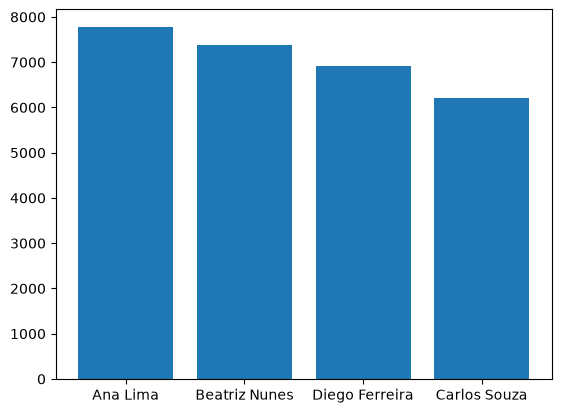

In [48]:
plt.bar(vendedores, totais)

## 5.3 `plt.title()`: dizendo o que o gráfico mostra

Um bom título responde **o quê, onde e quando**. Com um título descritivo, rótulos nos eixos ficam redundantes.

Text(0.5, 1.0, 'Faturamento por vendedor - mar/2025')

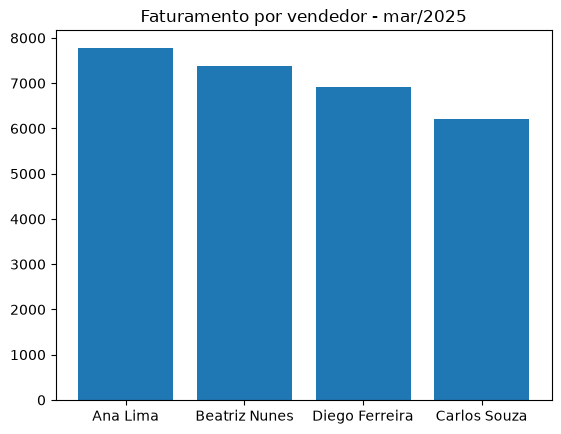

In [49]:
plt.bar(vendedores, totais)
plt.title('Faturamento por vendedor - mar/2025')

## 5.4 `plt.barh()`: barras horizontais

Mesma ideia, com as barras deitadas. É ótimo quando os nomes das categorias são longos. O `barh` desenha de baixo para cima; por isso ordenamos do **menor para o maior**, e o maior fica no topo.

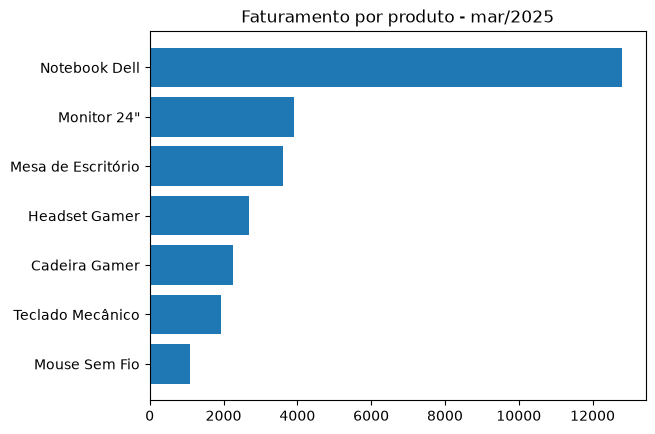

In [66]:
vendas_produto = df.groupby('Produto')['Total (R$)'].sum().reset_index()
vendas_produto = vendas_produto.sort_values(by='Total (R$)')

produtos = np.array(vendas_produto['Produto'])
total_produto = np.array(vendas_produto['Total (R$)'])

plt.barh(produtos, total_produto)
plt.title('Faturamento por produto - mar/2025')
plt.show()

## 5.5 Ajustes: tamanho, rotação e margens

- `plt.figure(figsize=(largura, altura))` define o tamanho da figura, em polegadas;
- `plt.xticks(rotation=45)` gira os nomes do eixo x para não se sobreporem;
- `plt.tight_layout()` ajusta as margens para nada ficar cortado.

Compare os dois gráficos abaixo: sem ajustes, os nomes se sobrepõem.

Text(0.5, 1.0, 'Faturamento por produto - mar/2025')

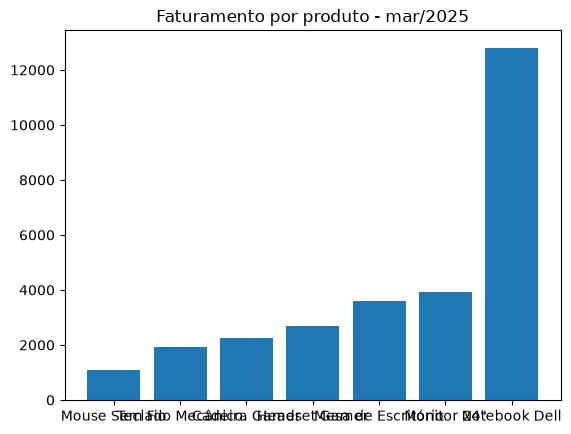

In [51]:
plt.bar(produtos, total_produto)
plt.title('Faturamento por produto - mar/2025')

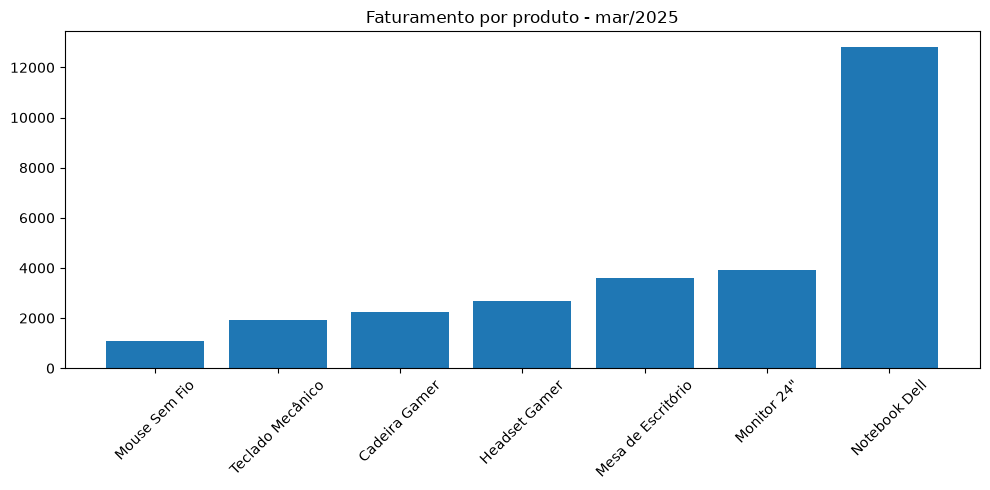

In [52]:
plt.figure(figsize=(10, 5))
plt.bar(produtos, total_produto)
plt.xticks(rotation=45)
plt.title('Faturamento por produto - mar/2025')
plt.tight_layout()

## 5.6 Exemplo: faturamento por categoria

Agrupar, ordenar, guardar em arrays, plotar e dar um título.

Text(0.5, 1.0, 'Faturamento por categoria - mar/2025')

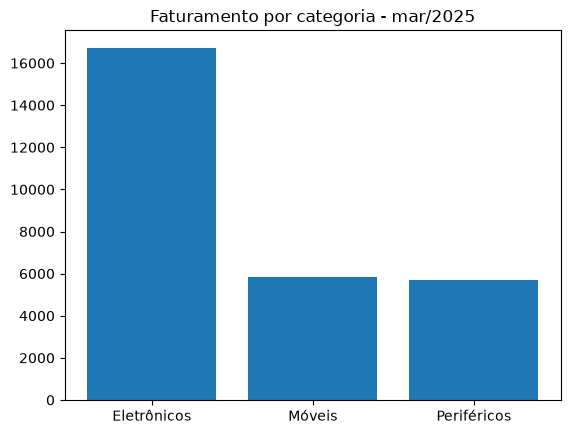

In [53]:
vendas_categoria = df.groupby('Categoria')['Total (R$)'].sum().reset_index()
vendas_categoria = vendas_categoria.sort_values(by='Total (R$)', ascending=False)

categorias = np.array(vendas_categoria['Categoria'])
total_categoria = np.array(vendas_categoria['Total (R$)'])

plt.bar(categorias, total_categoria)
plt.title('Faturamento por categoria - mar/2025')

## 5.7 Dados temporais com `plt.plot()`

Para dados no tempo, usamos a **linha**. Ela liga pontos consecutivos e por isso só faz sentido quando existe uma ordem, como o tempo. Vamos ver os furtos de celular no estado do RJ por ano.

O ano mais recente da base ainda está em andamento; por isso o recorte de 2015 a 2025 compara apenas anos completos.

Text(0.5, 1.0, 'Furtos de celular no RJ por ano')

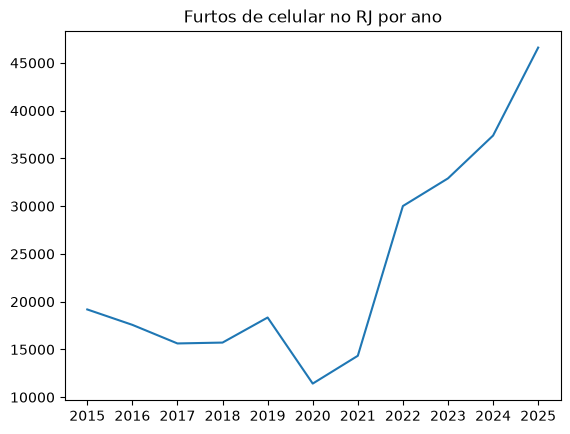

In [54]:
por_ano = isp.groupby('ano')['furto_celular'].sum().reset_index()
por_ano = por_ano.query('ano >= 2015 and ano <= 2025')

anos = np.array(por_ano['ano'])
furtos = np.array(por_ano['furto_celular'])

plt.plot(anos, furtos)
plt.xticks(anos)
plt.title('Furtos de celular no RJ por ano')

## 5.8 Linha ou barra?

Observe o mesmo faturamento por vendedor desenhado com linha: ela sugere uma continuidade entre vendedores que não existe.

**Regra:** `plt.plot()` para dados **temporais**; `plt.bar()` e `plt.barh()` para dados **categóricos**.

Text(0.5, 1.0, 'Faturamento por vendedor - mar/2025')

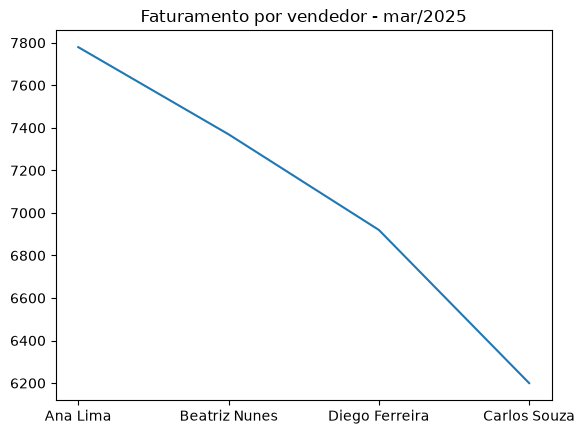

In [55]:
plt.plot(vendedores, totais)
plt.title('Faturamento por vendedor - mar/2025')

## 5.9 Menor valor, maior valor e amplitude total

Para o boxplot vamos retomar o array da Capital em 2024. Os extremos mostram a **amplitude total**: a distância entre o maior e o menor valor.

In [56]:
menor = dados.min()
maior = dados.max()
amplitude = maior - menor

print(menor, maior, amplitude)

32 2305 2273


## 5.10 Anatomia do boxplot

O boxplot resume a distribuição em uma única imagem:

| Elemento | O que representa |
|---|---|
| Caixa | de **Q1** a **Q3** (os 50% centrais) |
| Linha dentro da caixa | **mediana** (Q2) |
| Triângulo (com `showmeans=True`) | **média** |
| Bigodes | até o valor real mais extremo **dentro** dos limites do IQR (não até o limite teórico) |
| Círculos | **outliers** |

Se a média está à direita da mediana, os valores altos estão puxando a média para cima, o mesmo que a distância da Aula 3 indicava.

Text(0.5, 1.0, 'Furtos de celular por CISP - Capital 2024')

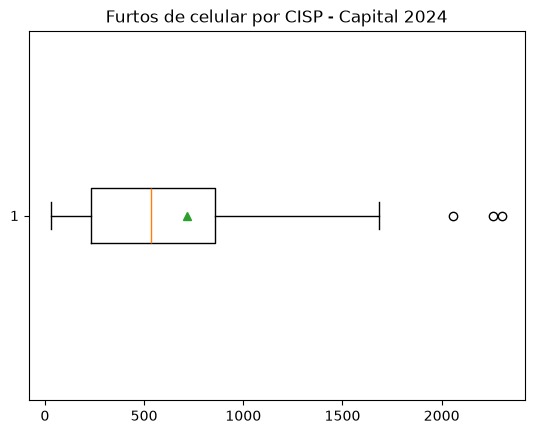

In [68]:
plt.boxplot(dados, orientation='horizontal',showmeans=True) #showmeans=True serve para aparecer a media 
plt.title('Furtos de celular por CISP - Capital 2024')

`orientation='horizontal'` deixa o boxplot deitado. Em versões do Matplotlib anteriores à 3.10, usava-se `vert=False`.

### Atividade 5.1 — Roubo de veículos na Baixada: três gráficos

Você é analista de dados de uma seguradora de veículos. Antes de revisar o preço das apólices na Baixada Fluminense, a diretoria pediu uma análise do **roubo de veículos** na região, usando a base do ISP-RJ (variável `roubo_veiculo`).

1. Quais municípios da Baixada concentraram mais roubos de veículos em 2024? A diretoria quer ver o ranking completo.
2. Como evoluiu o total de roubos de veículos na Baixada entre 2015 e 2025?
3. Considerando as CISPs da Baixada em 2024, os valores são parecidos entre si ou existem CISPs muito fora do padrão? A média representa bem esse conjunto?

Entregue cada resposta com um gráfico de título claro e uma conclusão de uma frase.

In [58]:
# Escreva seu código aqui

In [59]:
# Escreva seu código aqui

In [60]:
# Escreva seu código aqui

In [61]:
# Escreva seu código aqui

**Sua conclusão:** *(escreva aqui, em uma ou duas frases)*

## 5.11 Vários gráficos, uma só figura: `plt.subplots()`

Até aqui cada gráfico ocupou uma figura própria. Um **painel** reúne vários gráficos na mesma figura, organizados em linhas e colunas. Vantagens: comparação lado a lado, uma única imagem para relatórios e padronização do tamanho.

```python
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
```

- `fig` é a figura inteira, como uma folha de papel;
- `axes` é um array com os gráficos que ficam sobre a folha;
- os dois primeiros números são **linhas e colunas**: `(1, 2)` = 1 linha e 2 colunas;
- com uma linha só, usamos um índice: `axes[0]` é o gráfico da esquerda e `axes[1]` o da direita.

Em vez de `plt.bar()` usamos `axes[0].bar()`; em vez de `plt.title()`, `axes[0].set_title()`.

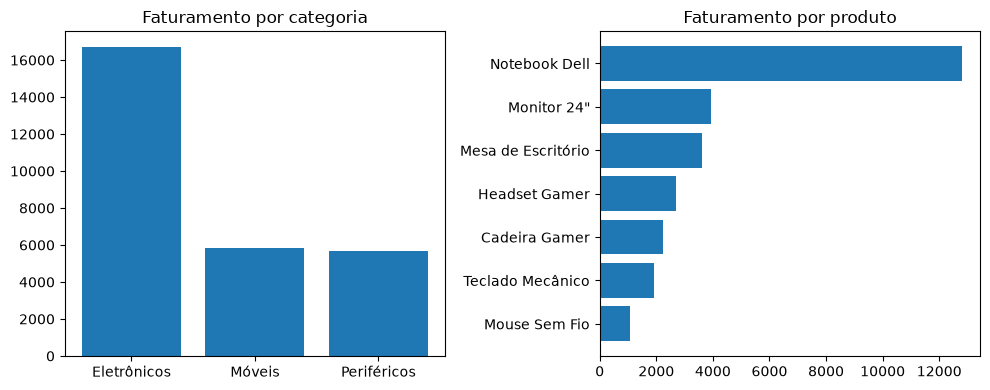

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(categorias, total_categoria)
axes[0].set_title('Faturamento por categoria')
axes[1].barh(produtos, total_produto)
axes[1].set_title('Faturamento por produto')
plt.tight_layout()

## 5.12 `plt.text()`: escrevendo dentro do gráfico

`plt.text(x, y, texto)` escreve o texto na posição (x, y) do gráfico. Em gráfico de barras, o x é a **posição da barra** (0 é a primeira) e o y é o valor. `ha='center'` centraliza o texto no ponto x e `color` muda a cor. Com **f-string**, o texto pode trazer valores calculados: `{valor:.2f}`.

Text(0.5, 1.0, 'Faturamento por vendedor - mar/2025')

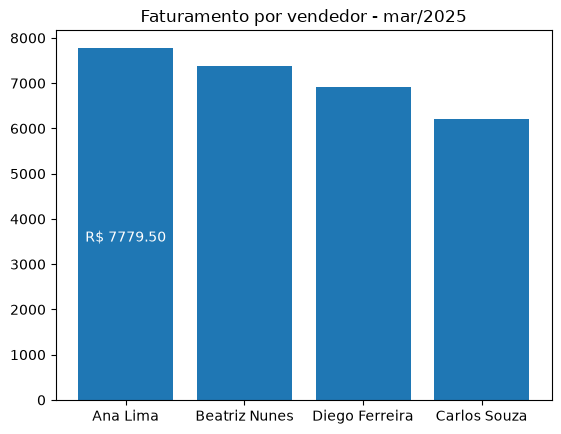

In [63]:
plt.bar(vendedores, totais)
plt.text(0, 3500, f'R$ {totais[0]:.2f}', ha='center', color='white')
plt.title('Faturamento por vendedor - mar/2025')

## 5.13 Calculando as medidas para o painel

Vamos montar um texto com as medidas da distribuição de furtos de celular por CISP na Capital, para escrever dentro do painel.

In [64]:
menor = dados.min()
maior = dados.max()
amplitude = maior - menor
q1 = np.percentile(dados, 25)
q2 = np.percentile(dados, 50)
q3 = np.percentile(dados, 75)
media = np.mean(dados)
mediana = np.median(dados)
distancia = (media - mediana) / mediana

texto = (f"Menor valor: {menor:.0f}\n"
         f"Q1: {q1:.1f}\n"
         f"Mediana (Q2): {q2:.1f}\n"
         f"Q3: {q3:.1f}\n"
         f"Maior valor: {maior:.0f}\n"
         f"Amplitude total: {amplitude:.0f}\n"
         f"Média: {media:.1f}\n"
         f"Distância média-mediana: {distancia:.1%}")

print(texto)

Menor valor: 32
Q1: 230.0
Mediana (Q2): 535.0
Q3: 859.0
Maior valor: 2305
Amplitude total: 2273
Média: 717.6
Distância média-mediana: 34.1%


## 5.14 Painel 1×2: boxplot e medidas

`axes[1].axis('off')` esconde bordas e números do eixo, deixando só o texto; `axes[1].text(x, y, texto)` segue a regra do `plt.text()`; `va='top'` alinha o texto pelo topo.

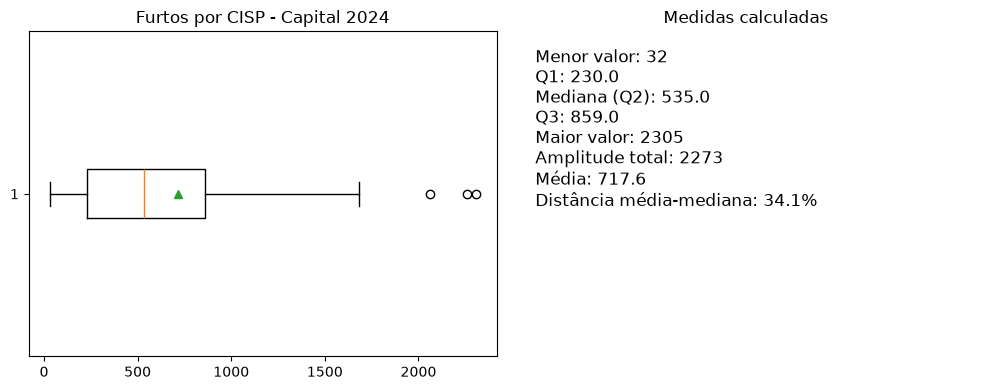

In [65]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].boxplot(dados, orientation='horizontal', showmeans=True)
axes[0].set_title('Furtos por CISP - Capital 2024')
axes[1].axis('off')
axes[1].text(0.05, 0.95, texto, va='top', fontsize=12)
axes[1].set_title('Medidas calculadas')
plt.tight_layout()

## 5.15 Painel 2×2: linhas e colunas

Com duas dimensões, o índice tem **linha e coluna**: `axes[linha, coluna]`. A contagem começa em zero: `axes[0, 0]` é o gráfico do canto superior esquerdo e `axes[1, 1]` o do canto inferior direito.

```python
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
```

Exemplo completo: quatro informações sobre os furtos de celular em uma única figura.

In [ ]:
top_cisp = por_cisp.sort_values(by='furto_celular', ascending=False).head(8)
top_cisp = top_cisp.sort_values(by='furto_celular')
nomes_cisp = np.array('CISP ' + top_cisp['cisp'].astype(str))
valores_cisp = np.array(top_cisp['furto_celular'])

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
axes[0, 0].plot(anos, furtos)
axes[0, 0].set_title('Furtos de celular no RJ por ano')
axes[0, 1].barh(nomes_cisp, valores_cisp)
axes[0, 1].set_title('Top 8 CISPs - Capital 2024')
axes[1, 0].boxplot(dados, orientation='horizontal', showmeans=True)
axes[1, 0].set_title('Furtos por CISP - Capital 2024')
axes[1, 1].axis('off')
axes[1, 1].text(0.05, 0.95, texto, va='top', fontsize=12)
axes[1, 1].set_title('Medidas calculadas')
plt.tight_layout()

### Atividade 5.2 — Painel executivo: roubo de celular na Capital

Você faz parte de uma consultoria contratada pela Secretaria de Segurança. Para a reunião de amanhã, o secretário quer **uma única imagem** com o panorama do roubo de celular na Capital do Rio de Janeiro, usando a base do ISP-RJ (variável `roubo_celular`).

- Como o roubo de celular na Capital evoluiu entre 2015 e 2025?
- Quais são as 8 CISPs com mais roubos de celular em 2024?
- Em 2024, a distribuição entre as CISPs é equilibrada? Existem CISPs fora do padrão?
- Um quadro com as medidas que sustentam a conclusão: menor e maior valor, amplitude, quartis, média e a distância entre média e mediana.

Reúna as quatro informações em uma só figura, com título claro em cada parte, e escreva uma conclusão de duas frases para o secretário.

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

**Sua conclusão:** *(escreva aqui, em uma ou duas frases)*

---
## Resumo das ferramentas

| Ferramenta | Para que serve |
|---|---|
| `pd.read_excel()`, `pd.read_csv()` | Ler planilhas e arquivos CSV |
| `groupby().sum().reset_index()` + `sort_values(by=...)` | Agrupar, somar e ordenar |
| `np.array()`, `np.mean()`, `np.median()`, `np.percentile()` | Estatística em arrays |
| `(média - mediana) / mediana` | Avaliar se a média é confiável |
| IQR e limites (`Q3 + 1,5 × IQR`, `Q1 - 1,5 × IQR`) | Identificar outliers |
| `plt.bar()` / `plt.barh()` | Comparar categorias |
| `plt.plot()` | Mostrar a evolução no tempo |
| `plt.boxplot(orientation='horizontal', showmeans=True)` | Ver distribuição, média, mediana e outliers |
| `plt.text()` | Escrever valores e medidas no gráfico |
| `fig, axes = plt.subplots(linhas, colunas)` | Montar painéis |